In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mean, std = 0.2860, 0.3530

In [ ]:
#Transformacje i wczytanie danych
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])
train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

ds_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=test_tf)
ds_aug = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

# Wydzielenie stałej walidacji (50k trening, 10k walidacja)
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(60000, generator=generator).tolist()
train_idx, val_idx = indices[:50000], indices[50000:]

train_plain_subset = Subset(ds_plain, train_idx)
train_aug_subset = Subset(ds_aug, train_idx)
val_subset = Subset(ds_plain, val_idx)

# DataLoadery
train_dl_plain = DataLoader(train_plain_subset, batch_size=128, shuffle=True)
train_dl_aug = DataLoader(train_aug_subset, batch_size=128, shuffle=True)
# Czysta ocena treningu (bez augmentacji i tasowania)
train_dl_eval = DataLoader(train_plain_subset, batch_size=128, shuffle=False)
val_dl = DataLoader(val_subset, batch_size=128, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.18MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 138kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.56MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.8MB/s]


In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [ ]:
def evaluate(model, dl):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)
    return total_loss / total, correct / total

In [ ]:
def run_training(model, train_dl, train_eval_dl, val_dl, epochs=10, lr=1e-3,
                 weight_decay=0.0, optimizer="adam", use_scheduler=False, verbose=False):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)


    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None

    hist = {"train_loss": [], "train_eval_loss": [], "val_loss": [], "val_acc": []}
    n = len(train_dl.dataset)

    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item()*yb.numel()

        if sched: sched.step()
        tr = run/n

        # Mierzenie strat w trybie eval(), na danych bez augmentacji, zgodnie z wymaganiami
        tr_eval, _ = evaluate(model, train_eval_dl)
        val, acc = evaluate(model, val_dl)

        hist["train_loss"].append(tr)
        hist["train_eval_loss"].append(tr_eval)
        hist["val_loss"].append(val)
        hist["val_acc"].append(acc)

        if verbose:
            print(f"Epoka {epoch:2d} | tren (aug) {tr:.3f} | tren (eval) {tr_eval:.3f} | walidacja {val:.3f} | acc {acc*100:.2f}%")

    return model, hist

In [ ]:
#URUCHOMIENIE EKSPERYMENTÓW
experiments = {}
epochs_budget = 15

print("Trenowanie: Baseline")
model_base, hist_base = run_training(MLP(), train_dl_plain, train_dl_eval, val_dl, epochs=epochs_budget)
experiments["Baseline"] = (model_base, hist_base)

print("Trenowanie: Wariant 1")
model_v1, hist_v1 = run_training(MLP(), train_dl_aug, train_dl_eval, val_dl, epochs=epochs_budget)
experiments["Wariant 1"] = (model_v1, hist_v1)

print("Trenowanie: Wariant 2")
model_v2, hist_v2 = run_training(MLP(use_bn=True, p_drop=0.3), train_dl_aug, train_dl_eval, val_dl, epochs=epochs_budget)
experiments["Wariant 2"] = (model_v2, hist_v2)

print("Trenowanie: Wariant 3")
model_v3, hist_v3 = run_training(MLP(use_bn=True, p_drop=0.3), train_dl_aug, train_dl_eval, val_dl, epochs=epochs_budget, weight_decay=1e-4, use_scheduler=True)
experiments["Wariant 3"] = (model_v3, hist_v3)

Trenowanie: Baseline
Trenowanie: Wariant 1
Trenowanie: Wariant 2
Trenowanie: Waria


In [ ]:
#WYNIKI
print("\n--- TABELA WYNIKÓW (wg najniższej straty walidacyjnej) ---")
best_overall_name = None
best_overall_val_loss = float('inf')

for name, (model, hist) in experiments.items():
    # epoka z najniższą stratą walidacyjną
    best_ep_idx = hist["val_loss"].index(min(hist["val_loss"]))

    v_loss = hist["val_loss"][best_ep_idx]
    v_acc = hist["val_acc"][best_ep_idx]
    t_eval_loss = hist["train_eval_loss"][best_ep_idx]
    gap = v_loss - t_eval_loss

    print(f"{name:12s} | Epoka: {best_ep_idx+1:2d} | Val Acc: {v_acc:.4f} | Luka train-val: {gap:.4f}")

    if v_loss < best_overall_val_loss:
        best_overall_val_loss = v_loss
        best_overall_name = name


--- TABELA WYNIKÓW (wg najniższej straty walidacyjnej) ---
Baseline     | Epoka:  5 | Val Acc: 0.8905 | Luka train-val: 0.0664
Wariant 1    | Epoka: 15 | Val Acc: 0.8422 | Luka train-val: 0.0203
Wariant 2    | Epoka: 15 | Val Acc: 0.8353 | Luka train-val: 0.0173
Wariant 3    | Epoka: 15 | Val Acc: 0.8260 | Luka train-val: 0.0162


In [ ]:
# Ocena końcowa na teście dla baseline i zwycięzcy
_, test_acc_base = evaluate(experiments["Baseline"][0], test_dl)
_, test_acc_best = evaluate(experiments[best_overall_name][0], test_dl)

print(f"OSTATECZNA OCENA NA ZBIORZE TESTOWYM")
print(f"Baseline Test Accuracy: {test_acc_base:.4f}")
print(f"Najlepszy ({best_overall_name}) Test Accuracy: {test_acc_best:.4f}")


--- OSTATECZNA OCENA NA ZBIORZE TESTOWYM ---
Baseline Test Accuracy: 0.8847
Najlepszy (Baseline) Test Accuracy: 0.8847


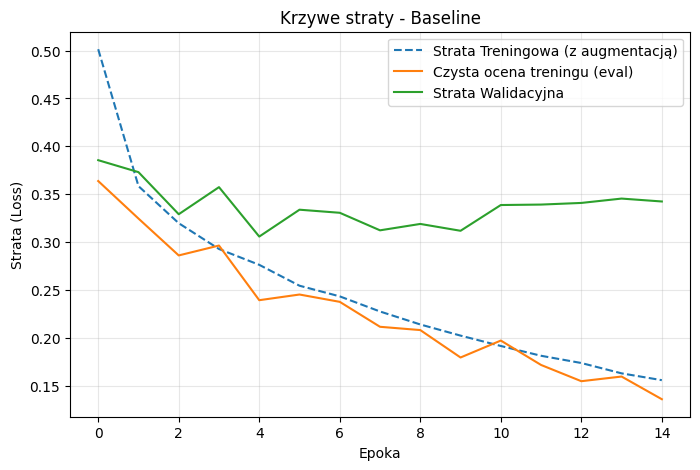

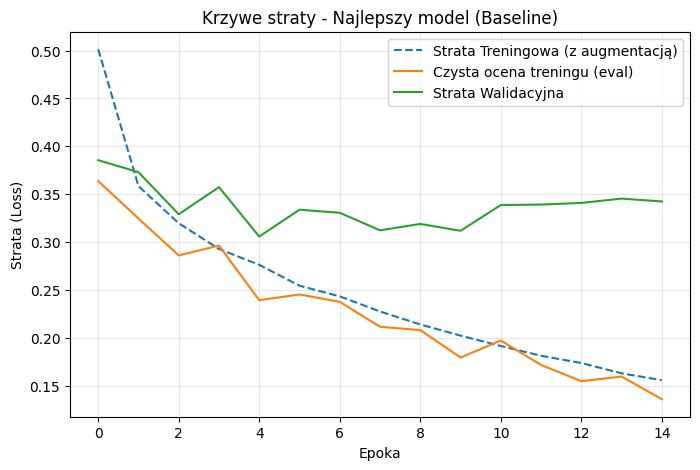

In [ ]:
# Wykresy uczenia
def plot_curves(name, hist):
    plt.figure(figsize=(8, 5))
    plt.plot(hist['train_loss'], '--', label='Strata Treningowa (z augmentacją)')
    plt.plot(hist['train_eval_loss'], '-', label='Czysta ocena treningu (eval)')
    plt.plot(hist['val_loss'], '-', label='Strata Walidacyjna')
    plt.title(f'Krzywe straty - {name}')
    plt.xlabel('Epoka')
    plt.ylabel('Strata (Loss)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_curves("Baseline", experiments["Baseline"][1])
plot_curves(f"Najlepszy model ({best_overall_name})", experiments[best_overall_name][1])